### SOAL RESPONSI NO 1

In [ ]:
!pip install google-play-scraper

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 2.1 MB/s eta 0:00:00


In [ ]:
from google_play_scraper import Sort, reviews
from google_play_scraper import app

import pandas as pd

import numpy as np

In [ ]:
# Scraping 200 data
result, continuation_token = reviews(
    'com.kiloo.subwaysurf',
    lang='id',
    country='id',
    sort= Sort.MOST_RELEVANT,
    count= 200,
    filter_score_with= None
)

In [ ]:
# membuat Dataframe dari hasil scraping
data = pd.DataFrame(np.array(result), columns=['review'])

data = data.join(pd.DataFrame(data.pop('review').tolist()))


In [ ]:
#mengambil fitur konten dan score
data = data[['content', 'score']]
data

,content,score
0,"Yah, akun saya tiba-tiba hilang, padahal udah ...",1
1,"keren banget sih ini, game yg cocok dimainkan ...",5
2,Game Subway ini tuh selalu dipertahankan dari ...,5
3,"waktu itu aku mainin subway surfers itu koin, ...",3
4,untuk gameplay nya bagus dan event yang menari...,5
...,...,...
195,"bagus banget permainan nya seru,tapi kadang ag...",4
196,game yang menarik dan menghilangkan bosan jika...,5
197,Wah bagus banget gamenya sekarang aku udah sko...,5
198,"cukup menyenangkan ,tapi harus lebih di kemban...",4


In [ ]:
#mengganti nama fitur
data = data.rename(columns={'content':'ulasan', 'score':'label'})
data1 = data.loc[data['label'], ['ulasan','label']]
data1.head()

,ulasan,label
1,"keren banget sih ini, game yg cocok dimainkan ...",5
5,knp sih gamenya sering bgt macet ditambah ke r...,1
5,knp sih gamenya sering bgt macet ditambah ke r...,1
3,"waktu itu aku mainin subway surfers itu koin, ...",3
5,knp sih gamenya sering bgt macet ditambah ke r...,1


In [ ]:
!pip install nltk

In [ ]:
import nltk
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [ ]:
# case folding
data1['case_folding'] = data1['ulasan'].apply(lambda x: x.lower())

data1.head()

,ulasan,label,case_folding
1,"keren banget sih ini, game yg cocok dimainkan ...",5,"keren banget sih ini, game yg cocok dimainkan ..."
5,knp sih gamenya sering bgt macet ditambah ke r...,1,knp sih gamenya sering bgt macet ditambah ke r...
5,knp sih gamenya sering bgt macet ditambah ke r...,1,knp sih gamenya sering bgt macet ditambah ke r...
3,"waktu itu aku mainin subway surfers itu koin, ...",3,"waktu itu aku mainin subway surfers itu koin, ..."
5,knp sih gamenya sering bgt macet ditambah ke r...,1,knp sih gamenya sering bgt macet ditambah ke r...


In [ ]:
# Cleaning (menghapus tanda baca)
import string

def remove_punctuation(text):
  table = str.maketrans('', '', string.punctuation)
  return text.translate(table)

data1['cleaning'] = data1['case_folding'].apply(remove_punctuation)

data1.head()

,ulasan,label,case_folding,cleaning
1,"keren banget sih ini, game yg cocok dimainkan ...",5,"keren banget sih ini, game yg cocok dimainkan ...",keren banget sih ini game yg cocok dimainkan s...
5,knp sih gamenya sering bgt macet ditambah ke r...,1,knp sih gamenya sering bgt macet ditambah ke r...,knp sih gamenya sering bgt macet ditambah ke r...
5,knp sih gamenya sering bgt macet ditambah ke r...,1,knp sih gamenya sering bgt macet ditambah ke r...,knp sih gamenya sering bgt macet ditambah ke r...
3,"waktu itu aku mainin subway surfers itu koin, ...",3,"waktu itu aku mainin subway surfers itu koin, ...",waktu itu aku mainin subway surfers itu koin k...
5,knp sih gamenya sering bgt macet ditambah ke r...,1,knp sih gamenya sering bgt macet ditambah ke r...,knp sih gamenya sering bgt macet ditambah ke r...


In [ ]:
# Tokenisasi
from nltk.tokenize import word_tokenize
import nltk

def tokenize_text(text):
  return word_tokenize(text)

data1['tokenisasi'] = data1['cleaning'].apply(tokenize_text)

data1.head()

,ulasan,label,case_folding,cleaning,tokenisasi
1,"keren banget sih ini, game yg cocok dimainkan ...",5,"keren banget sih ini, game yg cocok dimainkan ...",keren banget sih ini game yg cocok dimainkan s...,"[keren, banget, sih, ini, game, yg, cocok, dim..."
5,knp sih gamenya sering bgt macet ditambah ke r...,1,knp sih gamenya sering bgt macet ditambah ke r...,knp sih gamenya sering bgt macet ditambah ke r...,"[knp, sih, gamenya, sering, bgt, macet, ditamb..."
5,knp sih gamenya sering bgt macet ditambah ke r...,1,knp sih gamenya sering bgt macet ditambah ke r...,knp sih gamenya sering bgt macet ditambah ke r...,"[knp, sih, gamenya, sering, bgt, macet, ditamb..."
3,"waktu itu aku mainin subway surfers itu koin, ...",3,"waktu itu aku mainin subway surfers itu koin, ...",waktu itu aku mainin subway surfers itu koin k...,"[waktu, itu, aku, mainin, subway, surfers, itu..."
5,knp sih gamenya sering bgt macet ditambah ke r...,1,knp sih gamenya sering bgt macet ditambah ke r...,knp sih gamenya sering bgt macet ditambah ke r...,"[knp, sih, gamenya, sering, bgt, macet, ditamb..."


In [ ]:
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [ ]:
# Stopword Removal
stop_words = set(nltk.corpus.stopwords.words('indonesian'))

def remove_stopwords(tokens):
  return [word for word in tokens if word not in stop_words]

data1['stopwords_removed'] = data1['tokenisasi'].apply(remove_stopwords)

data1.head()

,ulasan,label,case_folding,cleaning,tokenisasi,stopwords_removed
1,"keren banget sih ini, game yg cocok dimainkan ...",5,"keren banget sih ini, game yg cocok dimainkan ...",keren banget sih ini game yg cocok dimainkan s...,"[keren, banget, sih, ini, game, yg, cocok, dim...","[keren, banget, sih, game, yg, cocok, dimainka..."
5,knp sih gamenya sering bgt macet ditambah ke r...,1,knp sih gamenya sering bgt macet ditambah ke r...,knp sih gamenya sering bgt macet ditambah ke r...,"[knp, sih, gamenya, sering, bgt, macet, ditamb...","[knp, sih, gamenya, bgt, macet, ditambah, rise..."
5,knp sih gamenya sering bgt macet ditambah ke r...,1,knp sih gamenya sering bgt macet ditambah ke r...,knp sih gamenya sering bgt macet ditambah ke r...,"[knp, sih, gamenya, sering, bgt, macet, ditamb...","[knp, sih, gamenya, bgt, macet, ditambah, rise..."
3,"waktu itu aku mainin subway surfers itu koin, ...",3,"waktu itu aku mainin subway surfers itu koin, ...",waktu itu aku mainin subway surfers itu koin k...,"[waktu, itu, aku, mainin, subway, surfers, itu...","[mainin, subway, surfers, koin, kunci, karakte..."
5,knp sih gamenya sering bgt macet ditambah ke r...,1,knp sih gamenya sering bgt macet ditambah ke r...,knp sih gamenya sering bgt macet ditambah ke r...,"[knp, sih, gamenya, sering, bgt, macet, ditamb...","[knp, sih, gamenya, bgt, macet, ditambah, rise..."


In [ ]:
!pip install Sastrawi

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 209.7/209.7 kB 5.4 MB/s eta 0:00:00


In [ ]:
# Stemming
import pandas as pd
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
factory = StemmerFactory()
stemmer = factory.create_stemmer()

In [ ]:
def stemming(teks):
    teks = str(teks)
    return stemmer.stem(teks)

data1['stemming'] = data1['stopwords_removed'].apply(stemming)
data1.head()

,ulasan,label,case_folding,cleaning,tokenisasi,stopwords_removed,stemming
1,"keren banget sih ini, game yg cocok dimainkan ...",5,"keren banget sih ini, game yg cocok dimainkan ...",keren banget sih ini game yg cocok dimainkan s...,"[keren, banget, sih, ini, game, yg, cocok, dim...","[keren, banget, sih, game, yg, cocok, dimainka...",keren banget sih game yg cocok main bosen gabu...
5,knp sih gamenya sering bgt macet ditambah ke r...,1,knp sih gamenya sering bgt macet ditambah ke r...,knp sih gamenya sering bgt macet ditambah ke r...,"[knp, sih, gamenya, sering, bgt, macet, ditamb...","[knp, sih, gamenya, bgt, macet, ditambah, rise...",knp sih gamenya bgt macet tambah riset dah ngu...
5,knp sih gamenya sering bgt macet ditambah ke r...,1,knp sih gamenya sering bgt macet ditambah ke r...,knp sih gamenya sering bgt macet ditambah ke r...,"[knp, sih, gamenya, sering, bgt, macet, ditamb...","[knp, sih, gamenya, bgt, macet, ditambah, rise...",knp sih gamenya bgt macet tambah riset dah ngu...
3,"waktu itu aku mainin subway surfers itu koin, ...",3,"waktu itu aku mainin subway surfers itu koin, ...",waktu itu aku mainin subway surfers itu koin k...,"[waktu, itu, aku, mainin, subway, surfers, itu...","[mainin, subway, surfers, koin, kunci, karakte...",mainin subway surfers koin kunci karakter lain...
5,knp sih gamenya sering bgt macet ditambah ke r...,1,knp sih gamenya sering bgt macet ditambah ke r...,knp sih gamenya sering bgt macet ditambah ke r...,"[knp, sih, gamenya, sering, bgt, macet, ditamb...","[knp, sih, gamenya, bgt, macet, ditambah, rise...",knp sih gamenya bgt macet tambah riset dah ngu...


In [ ]:
# Kategori Sentimen
def sentimen(score):
    if score >= 3:
        return 'positif'
    else:
        return 'negatif'

data1['sentimen'] = data1['label'].apply(sentimen)
data1.head()

,ulasan,label,case_folding,cleaning,tokenisasi,stopwords_removed,stemming,sentimen
1,"keren banget sih ini, game yg cocok dimainkan ...",5,"keren banget sih ini, game yg cocok dimainkan ...",keren banget sih ini game yg cocok dimainkan s...,"[keren, banget, sih, ini, game, yg, cocok, dim...","[keren, banget, sih, game, yg, cocok, dimainka...",keren banget sih game yg cocok main bosen gabu...,positif
5,knp sih gamenya sering bgt macet ditambah ke r...,1,knp sih gamenya sering bgt macet ditambah ke r...,knp sih gamenya sering bgt macet ditambah ke r...,"[knp, sih, gamenya, sering, bgt, macet, ditamb...","[knp, sih, gamenya, bgt, macet, ditambah, rise...",knp sih gamenya bgt macet tambah riset dah ngu...,negatif
5,knp sih gamenya sering bgt macet ditambah ke r...,1,knp sih gamenya sering bgt macet ditambah ke r...,knp sih gamenya sering bgt macet ditambah ke r...,"[knp, sih, gamenya, sering, bgt, macet, ditamb...","[knp, sih, gamenya, bgt, macet, ditambah, rise...",knp sih gamenya bgt macet tambah riset dah ngu...,negatif
3,"waktu itu aku mainin subway surfers itu koin, ...",3,"waktu itu aku mainin subway surfers itu koin, ...",waktu itu aku mainin subway surfers itu koin k...,"[waktu, itu, aku, mainin, subway, surfers, itu...","[mainin, subway, surfers, koin, kunci, karakte...",mainin subway surfers koin kunci karakter lain...,positif
5,knp sih gamenya sering bgt macet ditambah ke r...,1,knp sih gamenya sering bgt macet ditambah ke r...,knp sih gamenya sering bgt macet ditambah ke r...,"[knp, sih, gamenya, sering, bgt, macet, ditamb...","[knp, sih, gamenya, bgt, macet, ditambah, rise...",knp sih gamenya bgt macet tambah riset dah ngu...,negatif


In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

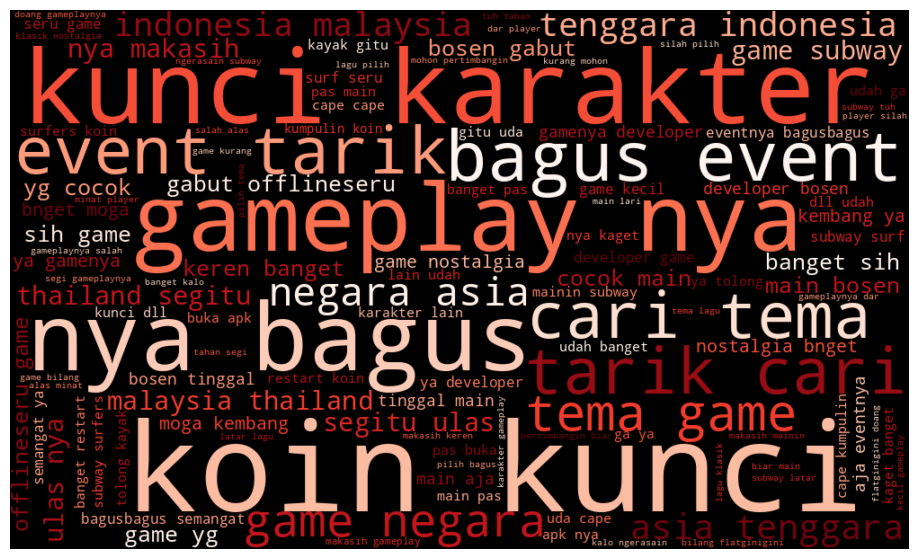

In [ ]:
# WordCloud Sentimen Positif
teks_positif = " ".join(data1[data1['sentimen'] == 'positif']['stemming'])

wordcloud = WordCloud(width=1000, height=600,
                      background_color='black',
                      colormap='Reds',
                      max_words=200).generate(teks_positif)

plt.figure(figsize=(12, 7))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.show()


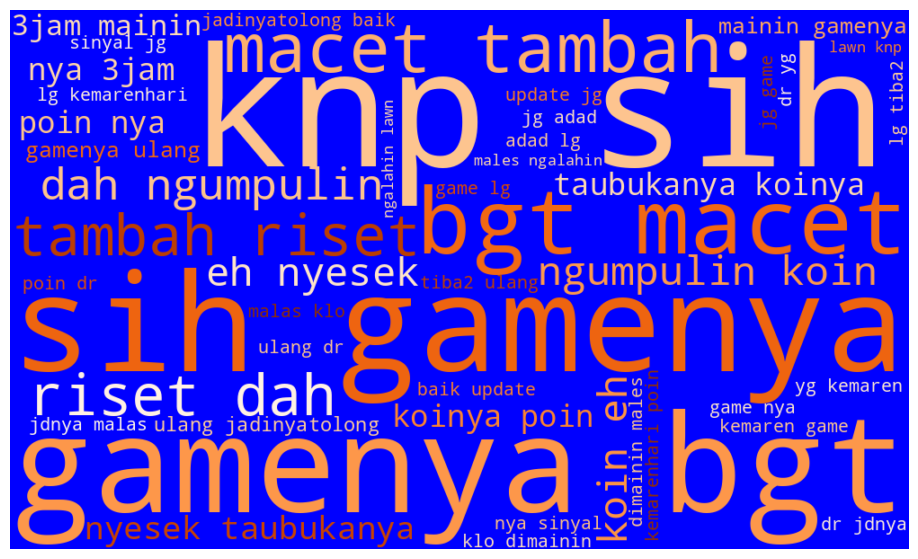

In [ ]:
# WordCloud Sentimen Negatif
teks_positif = " ".join(data1[data1['sentimen'] == 'negatif']['stemming'])

wordcloud = WordCloud(width=1000, height=600,
                      background_color='Blue',
                      colormap='Oranges',
                      max_words=200).generate(teks_positif)

plt.figure(figsize=(12, 7))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.show()

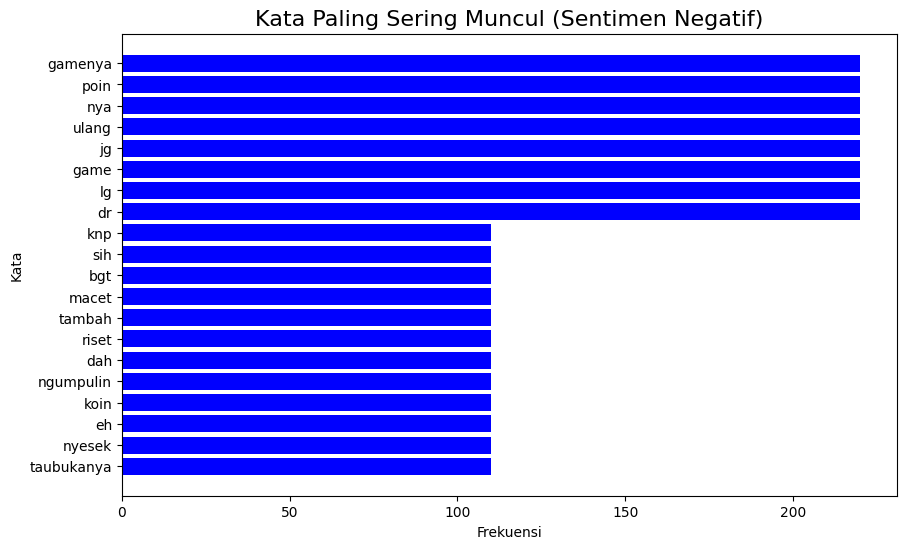

In [ ]:
# WordClud Ulasan Negatif dalam bentuk bar chart
from collections import Counter
import matplotlib.pyplot as plt
import pandas as pd

teks_negatif = " ".join(data1[data1['sentimen'] == 'negatif']['stemming'])
kata_negatif = teks_negatif.split()
frekuensi_kata = Counter(kata_negatif)

# Ambil 20 kata paling sering muncul
kata = pd.DataFrame(frekuensi_kata.most_common(20),
                            columns=['Kata', 'Frekuensi'])

plt.figure(figsize=(10,6))
plt.barh(kata['Kata'], kata['Frekuensi'], color='blue')
plt.gca().invert_yaxis()
plt.title('Kata Paling Sering Muncul (Sentimen Negatif)', fontsize=16)
plt.xlabel('Frekuensi')
plt.ylabel('Kata')
plt.show()


In [ ]:
data1.to_csv('hasil_scraping.csv', index=False)

Berdasarkan kata yang sering muncul pada ulasan negatif, saran saya untuk developer adalah:

1.   Memperbaiki kinerja dan bug karna banyak ulasan yang menyatakan jika game tiba - tiba berhenti atau tidak berjalan lancar. Oleh karena itu, perlu dilakukan perbaikan bug dan optimasi kinerja agar game dapat berjalan stabil
2.   Memperbaiki sistem progress (pause) dan penyimpanan koin karna banyak ulasan yang menyatakan jika banyak koin yang hilang dan harus mengulang dari awal saat game dijeda. oleh karena itu, perlu diperbaiki tentang penyimpanan koin saat game terjeda agar game lebih stabil dan fleksibel
3.   Melakukan riset untuk menambah inovasi pada game agar pengalaman bermain tambah seru dan tidak membosankan